<a href="https://colab.research.google.com/github/hailuu684/ECNU_Remote_Sensing_Data_Processing/blob/main/homework2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%cd /content/drive/MyDrive/PhD/ECNU/Remote_sensing_data_processing/homework2/dataset_level_1/
!tar -xvf LC08_L1TP_118038_20260817_20260823_02_T1.tar

/content/drive/MyDrive/PhD/ECNU/Remote_sensing_data_processing/homework2/dataset_level_1
LC08_L1TP_118038_20260817_20260823_02_T1_ANG.txt
LC08_L1TP_118038_20260817_20260823_02_T1_B1.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_B10.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_B11.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_B2.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_B3.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_B4.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_B5.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_B6.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_B7.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_B8.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_B9.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_MTL.json
LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
LC08_L1TP_118038_20260817_20260823_02_T1_MTL.xml
LC08_L1TP_118038_20260817_20260823_02_T1_QA_PIXEL.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_QA_RADSAT.TIF
LC08_L1TP_118038_20260817_20260823_02_T1_SAA.TIF
LC08_L1TP_118038_20260817_

In [ ]:
%cd /content/drive/MyDrive/PhD/ECNU/Remote_sensing_data_processing/homework2/dataset_level_2/

/content/drive/MyDrive/PhD/ECNU/Remote_sensing_data_processing/homework2/dataset_level_2


In [ ]:
!tar -xvf LC08_L2SP_118038_20260817_20260823_02_T1.tar

LC08_L2SP_118038_20260817_20260823_02_T1_ANG.txt
LC08_L2SP_118038_20260817_20260823_02_T1_MTL.json
LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt
LC08_L2SP_118038_20260817_20260823_02_T1_MTL.xml
LC08_L2SP_118038_20260817_20260823_02_T1_QA_PIXEL.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_QA_RADSAT.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_SR_B1.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_SR_B2.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_SR_B3.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_SR_B4.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_SR_B5.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_SR_B6.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_SR_B7.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_SR_QA_AEROSOL.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_SR_stac.json
LC08_L2SP_118038_20260817_20260823_02_T1_ST_ATRAN.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_ST_B10.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_ST_CDIST.TIF
LC08_L2SP_118038_20260817_20260823_02_T1_ST_DRAD.TIF
LC08_L2SP_1

In [ ]:
%cd /content/drive/MyDrive/PhD/ECNU/Remote_sensing_data_processing/homework2

/content/drive/MyDrive/PhD/ECNU/Remote_sensing_data_processing/homework2


In [1]:
import os
import gc
import glob

import numpy as np
import rasterio
import matplotlib
import matplotlib.pyplot as plt
from scipy import ndimage

In [2]:
class LandsatDataLoader:
    # Band mapping table for Landsat 8/9 OLI
    BAND_INFO = {
        1: {"name": "Coastal Aerosol", "wavelength": "0.43 - 0.45 µm"},
        2: {"name": "Blue", "wavelength": "0.45 - 0.51 µm"},
        3: {"name": "Green", "wavelength": "0.53 - 0.59 µm"},
        4: {"name": "Red", "wavelength": "0.64 - 0.67 µm"},
        5: {"name": "Near Infrared (NIR)", "wavelength": "0.85 - 0.88 µm"},
        6: {"name": "Shortwave Infrared 1 (SWIR 1)", "wavelength": "1.57 - 1.65 µm"},
        7: {"name": "Shortwave Infrared 2 (SWIR 2)", "wavelength": "2.11 - 2.29 µm"},
    }

    def __init__(self):
        self.mult_infor = None
        self.add_infor = None

    # ---------- file handling ----------
    @staticmethod
    def _find_file(directory, suffix):
        """Return the first file in `directory` whose name ends with `suffix`."""
        matches = sorted(glob.glob(os.path.join(directory, f"*{suffix}")))
        if not matches:
            raise FileNotFoundError(f"No file ending with '{suffix}' in {directory}")
        return matches[0]

    # ---------- metadata ----------
    @staticmethod
    def parse_mtl(mtl_filepath):
        found = {}                       # group name -> {'MULT': {...}, 'ADD': {...}}
        current_group = None
        with open(mtl_filepath, 'r') as f:
            for line in f:
                s = line.strip()
                if s.startswith("GROUP ="):
                    current_group = s.split("=")[1].strip()
                    continue
                if s.startswith("END_GROUP"):
                    current_group = None
                    continue
                if "REFLECTANCE_MULT_BAND_" in s or "REFLECTANCE_ADD_BAND_" in s:
                    key, value = s.split("=")
                    kind = 'MULT' if "MULT" in key else 'ADD'
                    band = int(key.strip().split("_")[-1])
                    found.setdefault(current_group, {'MULT': {}, 'ADD': {}})[kind][band] = float(value)

        print("Groups with reflectance coefficients:", list(found.keys()))
        for group in ("LEVEL2_SURFACE_REFLECTANCE_PARAMETERS", "LEVEL1_RADIOMETRIC_RESCALING"):
            if group in found:
                print(f"Using group {group} from {os.path.basename(mtl_filepath)}")
                return found[group]
        raise ValueError(f"No reflectance coefficients found in {mtl_filepath}")

    # ---------- DN -> reflectance ----------
    def load_reflectance(self, data_dir, band):
        """Convert one band from DN to reflectance. Pixels with nodata become NaN."""
        mtl = self._find_file(data_dir, "_MTL.txt")
        tif = self._find_file(data_dir, f"_B{band}.TIF")

        coeffs = self.parse_mtl(mtl)
        mult = coeffs['MULT'].get(band)
        add = coeffs['ADD'].get(band)
        if mult is None or add is None:
            raise ValueError(f"Coefficients for band {band} not found in {mtl}")
        self.mult_infor, self.add_infor = mult, add

        with rasterio.open(tif) as src:
            dn = src.read(1)                     # native uint16, small in memory
            nodata = src.nodata

        valid = (dn != nodata) if nodata is not None else (dn > 0)

        refl = dn.astype(np.float32)             # one float32 copy
        del dn
        refl *= np.float32(mult)                 # in-place: refl = DN * MULT
        refl += np.float32(add)                  # in-place: refl = DN * MULT + ADD
        refl[~valid] = np.nan
        del valid
        gc.collect()
        return refl

    def print_coefficients(self, label=""):
        print(f"{label} MULT = {self.mult_infor}, ADD = {self.add_infor}")

    # ---------- straightening ----------
    @staticmethod
    def _best_angle(small_mask, angles):
        """Angle that gives the smallest bounding box around the valid footprint."""
        best_angle, best_area = angles[0], np.inf
        for angle in angles:
            rot = ndimage.rotate(small_mask, angle, reshape=True, order=0,
                                 mode='constant', cval=0) > 0
            area = np.count_nonzero(rot.any(axis=1)) * np.count_nonzero(rot.any(axis=0))
            if area < best_area:
                best_area, best_angle = area, angle
        return float(best_angle)

    def find_straightening_angle(self, valid):
        """Two-pass search: coarse (0.5 deg steps) on a 1/10 mask, then fine (0.02 deg) on a 1/4 mask."""
        coarse_mask = valid[::10, ::10].astype(np.uint8)
        coarse = self._best_angle(coarse_mask, np.arange(-45.0, 45.0 + 1e-9, 0.5))

        fine_mask = valid[::4, ::4].astype(np.uint8)
        fine = self._best_angle(fine_mask, np.arange(coarse - 0.5, coarse + 0.5 + 1e-9, 0.02))
        del coarse_mask, fine_mask
        return fine

    def straighten(self, refl):
        """Rotate the scene footprint upright and crop the empty border. Returns (image, angle_deg)."""
        valid = np.isfinite(refl)
        angle = self.find_straightening_angle(valid)

        filled = refl.copy()
        filled[~valid] = 0                       # NaN would spread through interpolation
        rot = ndimage.rotate(filled, angle, reshape=True, order=1,
                             mode='constant', cval=0)
        del filled
        mask = ndimage.rotate(valid.astype(np.uint8), angle, reshape=True,
                              order=0, mode='constant', cval=0) > 0
        del valid
        rot[~mask] = np.nan

        rows = np.flatnonzero(mask.any(axis=1))
        cols = np.flatnonzero(mask.any(axis=0))
        out = rot[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1].copy()  # copy frees the big array
        del rot, mask
        gc.collect()
        return out, angle

    # ---------- display ----------
    @staticmethod
    def for_display(img, max_side=1500):
        """Strided subsample so that the longest side is about max_side pixels (display only)."""
        step = max(1, int(np.ceil(max(img.shape) / max_side)))
        return img[::step, ::step]

    def visualize_comparison(self, toa, sr, band, max_side=1500, cmap='gray'):
        """Level 1 (TOA) on the left, Level 2 (SR) on the right, one shared colorbar."""
        toa_d = self.for_display(toa, max_side)
        sr_d = self.for_display(sr, max_side)

        both = np.concatenate([toa_d[np.isfinite(toa_d)], sr_d[np.isfinite(sr_d)]])
        vmin, vmax = np.percentile(both, [2, 98])

        cmap_obj = matplotlib.colormaps[cmap].copy()
        cmap_obj.set_bad(color='black')          # outside the scene: black

        info = self.BAND_INFO.get(band, {"name": f"Band {band}", "wavelength": "Unknown"})
        band_title = f"Band {band} ({info['name']} - {info['wavelength']})"

        fig, axes = plt.subplots(1, 2, figsize=(16, 8))
        panels = [(axes[0], toa_d, "Level 1: TOA Reflectance"),
                  (axes[1], sr_d, "Level 2: Surface Reflectance (SR)")]
        im = None
        for ax, img, name in panels:
            im = ax.imshow(img, cmap=cmap_obj, vmin=vmin, vmax=vmax)
            ax.set_title(f"{name}\n{band_title}", fontsize=11)
            ax.axis('off')

        # One legend (colorbar) shared by both images
        fig.colorbar(im, ax=list(axes), label='Reflectance', fraction=0.03, pad=0.02)
        plt.show()

Groups with reflectance coefficients: ['LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL1_RADIOMETRIC_RESCALING from LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
Level 1 (TOA): MULT = 2e-05, ADD = -0.1
Groups with reflectance coefficients: ['LEVEL2_SURFACE_REFLECTANCE_PARAMETERS', 'LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL2_SURFACE_REFLECTANCE_PARAMETERS from LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt
Level 2 (SR): MULT = 2.75e-05, ADD = -0.2
TOA shape: (7851, 7711) | SR shape: (7851, 7711)
Straightening angle - Level 1: 13.48 deg | Level 2: 13.48 deg
Straightened shapes: (6554, 6345) (6554, 6205)


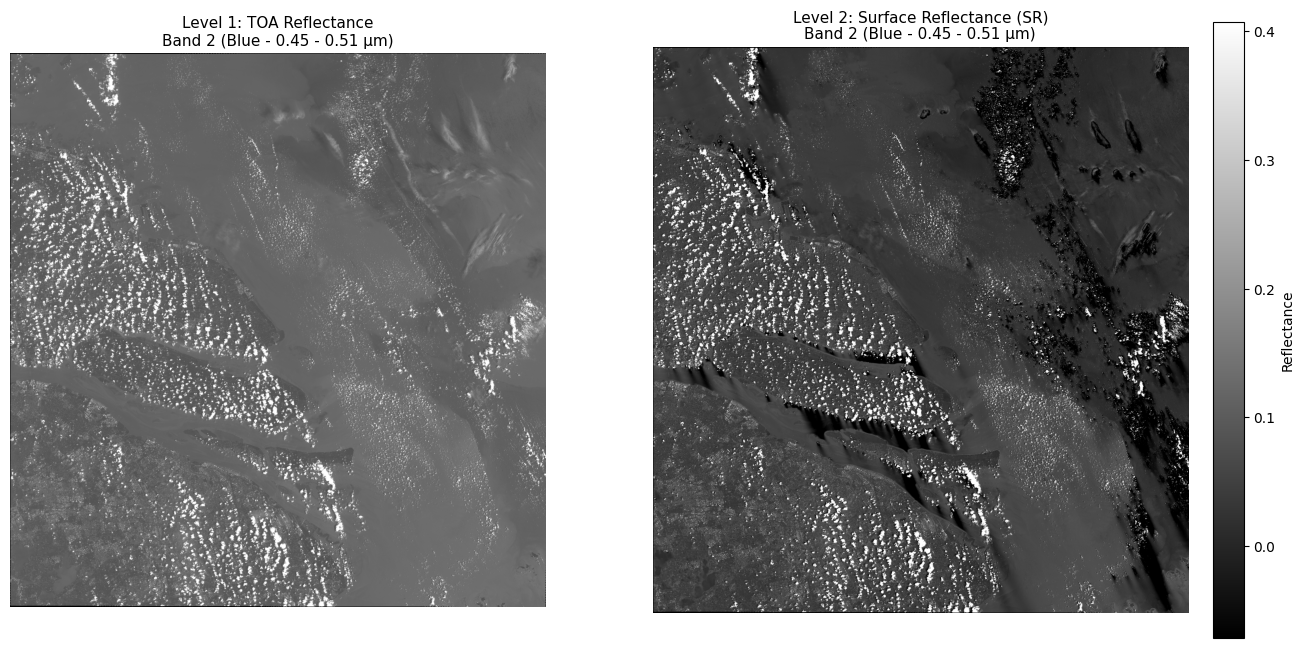

In [8]:
# ==========================================
# Execution Example for Google Colab
# ==========================================

# 1. Define paths
LEVEL1_DIR = "/content/drive/MyDrive/PhD/ECNU/Remote_sensing_data_processing/homework2/dataset_level_1"
LEVEL2_DIR = "/content/drive/MyDrive/PhD/ECNU/Remote_sensing_data_processing/homework2/dataset_level_2"

loader = LandsatDataLoader()

BAND = 2
# Copy only the files we need to the local Colab disk
toa = loader.load_reflectance(LEVEL1_DIR, BAND)
loader.print_coefficients("Level 1 (TOA):")
sr = loader.load_reflectance(LEVEL2_DIR, BAND)
loader.print_coefficients("Level 2 (SR):")

print("TOA shape:", toa.shape, "| SR shape:", sr.shape)

# Straighten each product (free the unrotated array right after use)
toa_s, angle_toa = loader.straighten(toa)
del toa
gc.collect()

sr_s, angle_sr = loader.straighten(sr)
del sr
gc.collect()

print(f"Straightening angle - Level 1: {angle_toa:.2f} deg | Level 2: {angle_sr:.2f} deg")
print("Straightened shapes:", toa_s.shape, sr_s.shape)


# 4. Visualise: Level 1 (left) vs Level 2 (right), one legend


loader.visualize_comparison(toa_s, sr_s, BAND)

In [3]:
BANDS = [2, 5]
STRAIGHTEN = True

In [4]:
def show_coefficients(label, data_dir):
    """Print MULT and ADD of every band in the _MTL.txt file of one level."""
    mtl = loader._find_file(data_dir, "_MTL.txt")
    coeffs = loader.parse_mtl(mtl)       # returns {'MULT': {...}, 'ADD': {...}}
    mult, add = coeffs['MULT'], coeffs['ADD']
    print("=" * 60)
    print(label, "| MTL file:", os.path.basename(mtl))
    print(f"{'Band':>6} {'MULT':>14} {'ADD':>12}")
    for band in sorted(mult):
        mark = "  <-- used" if band in BANDS else ""
        print(f"{band:>6} {mult[band]:>14.6e} {add.get(band, float('nan')):>12.6f}{mark}")
    print()
    return mult, add

Groups with reflectance coefficients: ['LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL1_RADIOMETRIC_RESCALING from LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
LEVEL 1 (TOA) | MTL file: LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
  Band           MULT          ADD
     1   2.000000e-05    -0.100000
     2   2.000000e-05    -0.100000  <-- used
     3   2.000000e-05    -0.100000
     4   2.000000e-05    -0.100000
     5   2.000000e-05    -0.100000  <-- used
     6   2.000000e-05    -0.100000
     7   2.000000e-05    -0.100000
     8   2.000000e-05    -0.100000
     9   2.000000e-05    -0.100000

Groups with reflectance coefficients: ['LEVEL2_SURFACE_REFLECTANCE_PARAMETERS', 'LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL2_SURFACE_REFLECTANCE_PARAMETERS from LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt
LEVEL 2 (SR) | MTL file: LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt
  Band           MULT          ADD
     1   2.750000e-05    -0.200000
     2   2.750000e-05    -0.

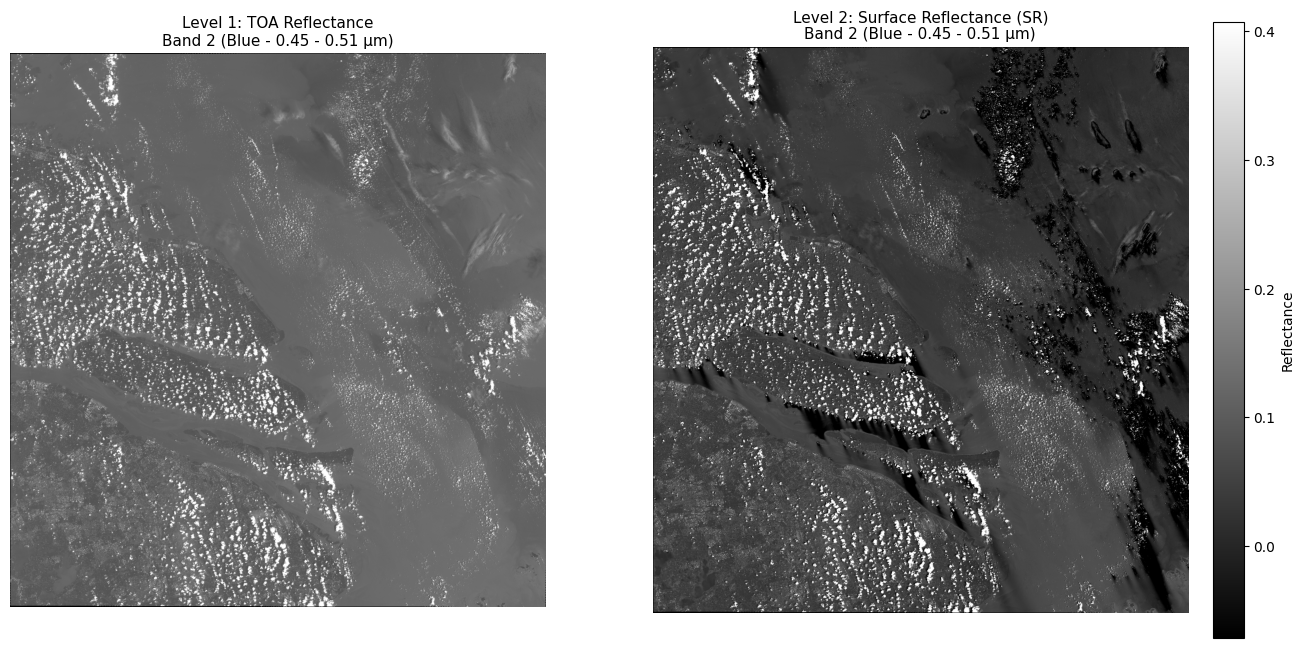

--- Band 5 ---
Level 1: MULT = 2.000000e-05, ADD = -0.100000
Level 2: MULT = 2.750000e-05, ADD = -0.200000
Groups with reflectance coefficients: ['LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL1_RADIOMETRIC_RESCALING from LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
Groups with reflectance coefficients: ['LEVEL2_SURFACE_REFLECTANCE_PARAMETERS', 'LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL2_SURFACE_REFLECTANCE_PARAMETERS from LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt
Straightening angle: Level 1 = 13.48 deg, Level 2 = 13.48 deg


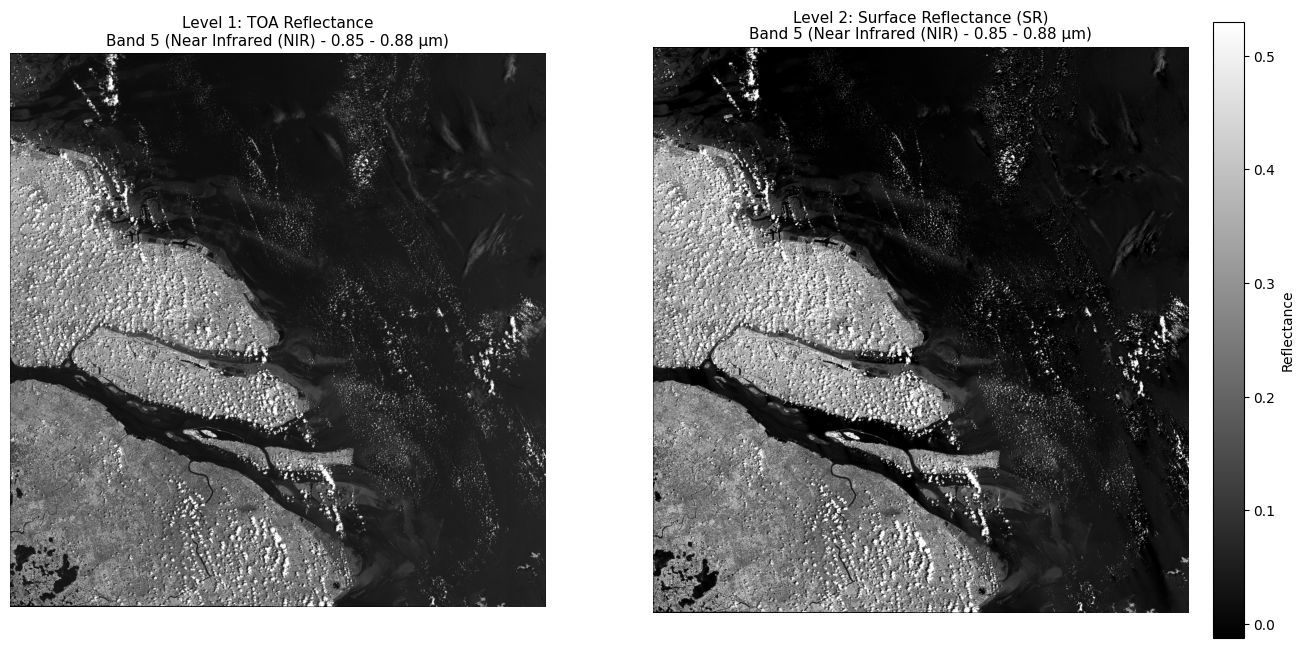

In [7]:

# 1. Define paths
LEVEL1_DIR = "/content/drive/MyDrive/PhD/ECNU/Remote_sensing_data_processing/homework2/dataset_level_1"
LEVEL2_DIR = "/content/drive/MyDrive/PhD/ECNU/Remote_sensing_data_processing/homework2/dataset_level_2"

loader = LandsatDataLoader()

mult1, add1 = show_coefficients("LEVEL 1 (TOA)", LEVEL1_DIR)
mult2, add2 = show_coefficients("LEVEL 2 (SR)", LEVEL2_DIR)

for band in BANDS:
    print(f"--- Band {band} ---")
    print(f"Level 1: MULT = {mult1[band]:.6e}, ADD = {add1[band]:.6f}")
    print(f"Level 2: MULT = {mult2[band]:.6e}, ADD = {add2[band]:.6f}")

    toa = loader.load_reflectance(LEVEL1_DIR, band)
    sr = loader.load_reflectance(LEVEL2_DIR, band)

    if STRAIGHTEN:
        toa, angle1 = loader.straighten(toa)
        sr, angle2 = loader.straighten(sr)
        print(f"Straightening angle: Level 1 = {angle1:.2f} deg, Level 2 = {angle2:.2f} deg")

    loader.visualize_comparison(toa, sr, band)   # Level 1 left, Level 2 right, one legend
    del toa, sr
    gc.collect()

In [9]:
def dn_at(tif, r, c):
    with rasterio.open(tif) as src:
        return int(src.read(1, window=((r, r + 1), (c, c + 1)))[0, 0])

refl5 = loader.load_reflectance(LEVEL2_DIR, 5)     # SR band 5, raw (unrotated) grid
pixels = {}
for name, target in {"water": 0.02, "vegetation": 0.35}.items():
    idx = np.nanargmin(np.abs(refl5 - target))
    pixels[name] = np.unravel_index(idx, refl5.shape)
del refl5

for name, (r, c) in pixels.items():
    print(f"\n{name}: row={r}, col={c}")
    for band in [2, 5]:
        dn1 = dn_at(loader._find_file(LEVEL1_DIR, f"_B{band}.TIF"), r, c)
        dn2 = dn_at(loader._find_file(LEVEL2_DIR, f"_B{band}.TIF"), r, c)
        toa = mult1[band] * dn1 + add1[band]
        sr = mult2[band] * dn2 + add2[band]
        wrong = mult1[band] * dn2 + add1[band]     # Level-1 coefficients applied to Level-2 DN
        print(f"  Band {band}: DN_L1={dn1}, TOA={toa:.4f} | DN_L2={dn2}, SR={sr:.4f} | "
              f"SR with L1 coeff={wrong:.4f}")

Groups with reflectance coefficients: ['LEVEL2_SURFACE_REFLECTANCE_PARAMETERS', 'LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL2_SURFACE_REFLECTANCE_PARAMETERS from LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt

water: row=79, col=1673
  Band 2: DN_L1=11302, TOA=0.1260 | DN_L2=9046, SR=0.0488 | SR with L1 coeff=0.0809
  Band 5: DN_L1=7244, TOA=0.0449 | DN_L2=8000, SR=0.0200 | SR with L1 coeff=0.0600

vegetation: row=197, col=1672
  Band 2: DN_L1=18766, TOA=0.2753 | DN_L2=17672, SR=0.2860 | SR with L1 coeff=0.2534
  Band 5: DN_L1=20239, TOA=0.3048 | DN_L2=20000, SR=0.3500 | SR with L1 coeff=0.3000


Groups with reflectance coefficients: ['LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL1_RADIOMETRIC_RESCALING from LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
Groups with reflectance coefficients: ['LEVEL2_SURFACE_REFLECTANCE_PARAMETERS', 'LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL2_SURFACE_REFLECTANCE_PARAMETERS from LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt
Band 2: TOA shape (7851, 7711), SR shape (7851, 7711), same shape: True


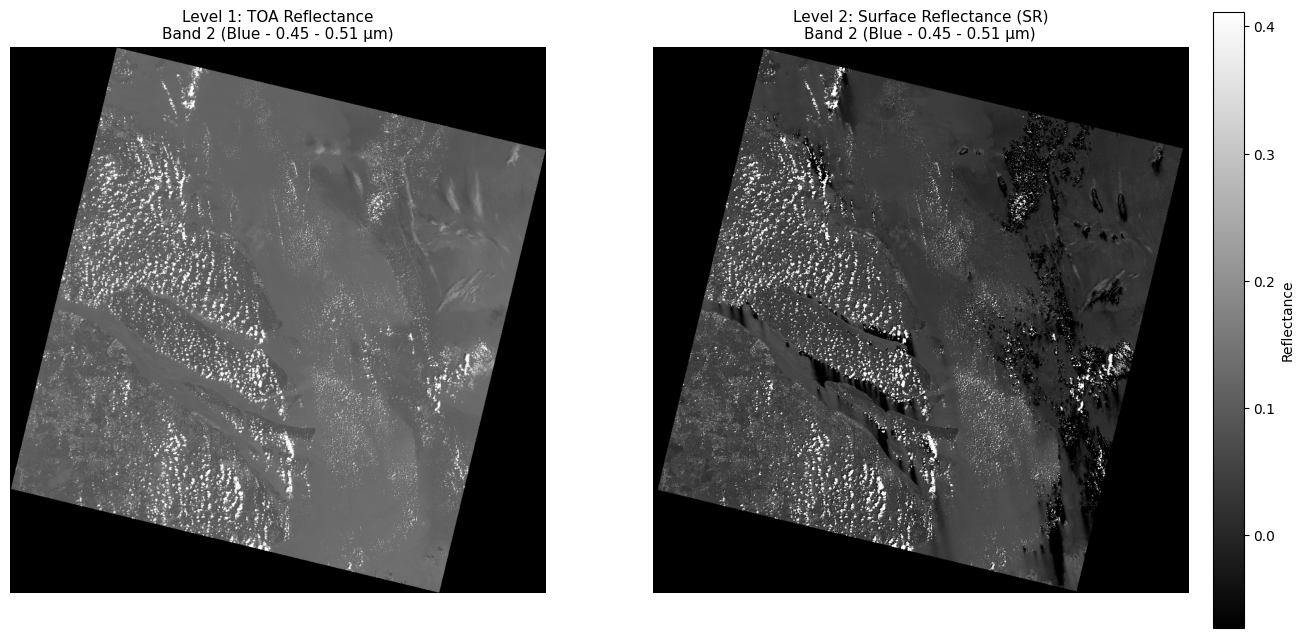

Groups with reflectance coefficients: ['LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL1_RADIOMETRIC_RESCALING from LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
Groups with reflectance coefficients: ['LEVEL2_SURFACE_REFLECTANCE_PARAMETERS', 'LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL2_SURFACE_REFLECTANCE_PARAMETERS from LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt
Band 5: TOA shape (7851, 7711), SR shape (7851, 7711), same shape: True


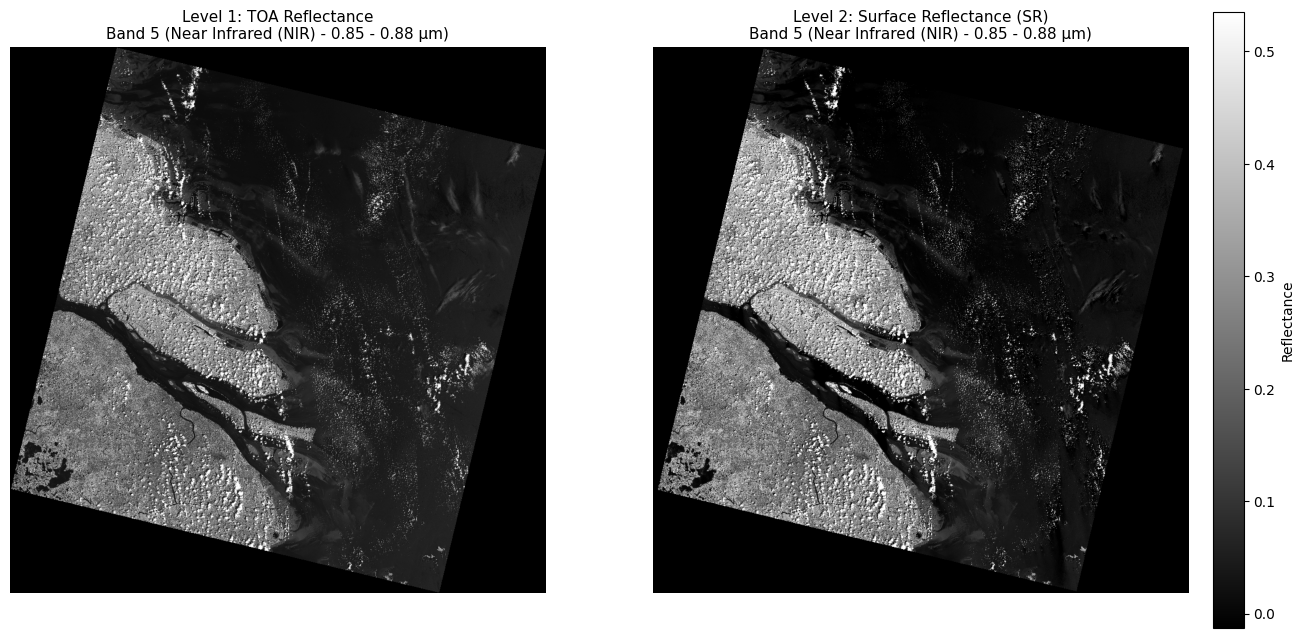

In [10]:
# Visualize TOA vs SR on the raw (unrotated) grid
for band in [2, 5]:
    toa = loader.load_reflectance(LEVEL1_DIR, band)
    sr = loader.load_reflectance(LEVEL2_DIR, band)
    print(f"Band {band}: TOA shape {toa.shape}, SR shape {sr.shape}, same shape: {toa.shape == sr.shape}")

    # Subsample by 4 only for display, so the plot renders quickly.
    # The full arrays toa and sr are kept for the statistics in Block 4.
    loader.visualize_comparison(toa[::4, ::4], sr[::4, ::4], band)

    del toa, sr
    gc.collect()

Groups with reflectance coefficients: ['LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL1_RADIOMETRIC_RESCALING from LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
Groups with reflectance coefficients: ['LEVEL2_SURFACE_REFLECTANCE_PARAMETERS', 'LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL2_SURFACE_REFLECTANCE_PARAMETERS from LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt
Groups with reflectance coefficients: ['LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL1_RADIOMETRIC_RESCALING from LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
Groups with reflectance coefficients: ['LEVEL2_SURFACE_REFLECTANCE_PARAMETERS', 'LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL2_SURFACE_REFLECTANCE_PARAMETERS from LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt


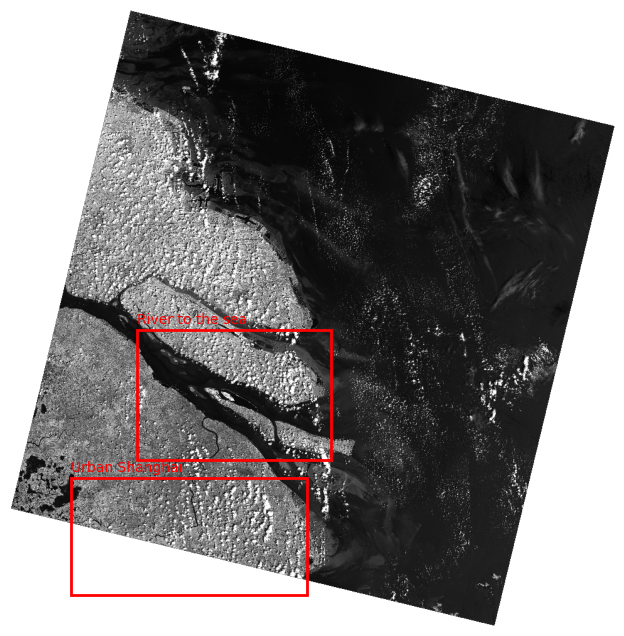

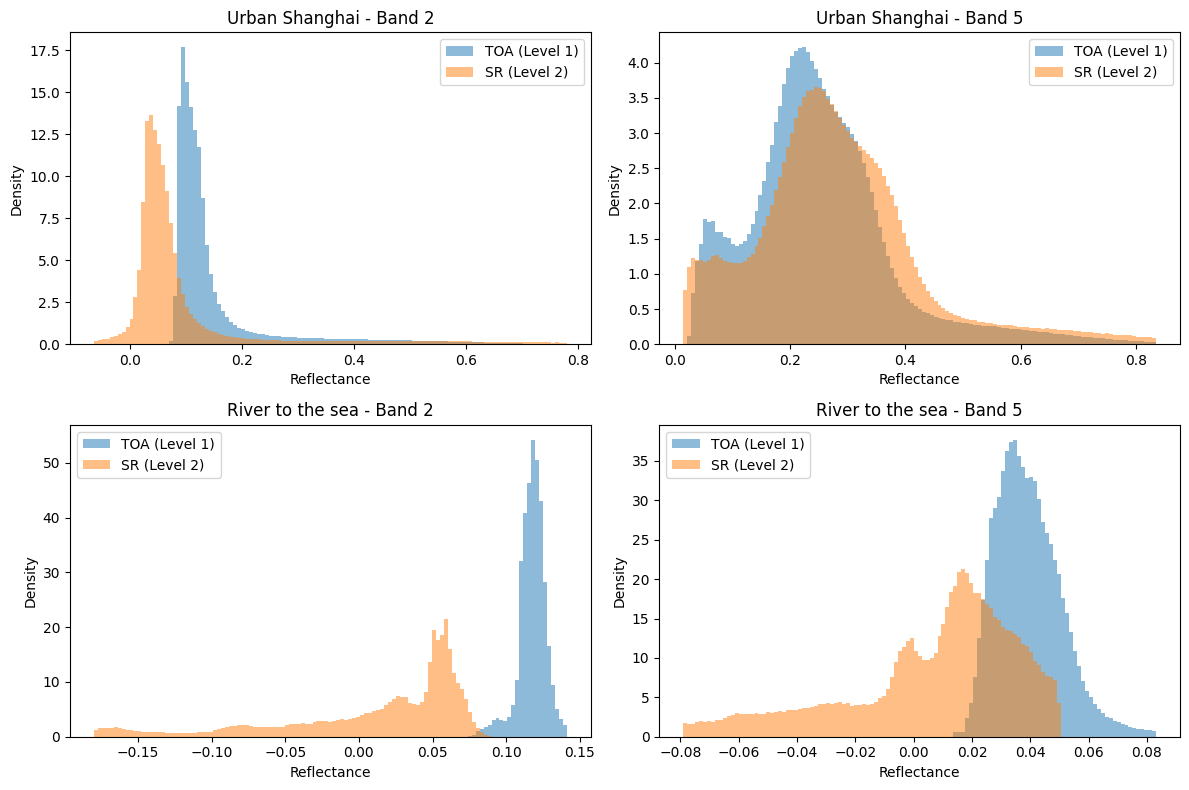

Region             Band    Pixels   TOA mean   TOA med   TOA std   SR mean    SR med    SR std   SR<0 %
Urban Shanghai        2   2817715     0.1522    0.1154    0.1070    0.1019    0.0537    0.1564    4.21%
Urban Shanghai        5   2818983     0.2526    0.2380    0.1314    0.2815    0.2655    0.1560    0.37%
River to the sea      2   1258229     0.1179    0.1184    0.0097    0.0079    0.0331    0.0665   31.71%
River to the sea      5   1263741     0.0399    0.0382    0.0124    0.0056    0.0138    0.0306   32.97%


In [13]:
BANDS = [2, 5]
WATER_SR_MAX = 0.05   # SR band 5 below this value is treated as water

# Each region: ((top, bottom, left, right) as fractions of the image, water_only)
# These boxes are first guesses. Check the preview and adjust them.
REGIONS = {
    "Urban Shanghai":   ((0.76, 0.95, 0.10, 0.49), False),
    "River to the sea": ((0.52, 0.73, 0.21, 0.53), True),
}

# 1. Load the raw (unrotated) arrays
arrays = {}
for band in BANDS:
    arrays[(1, band)] = loader.load_reflectance(LEVEL1_DIR, band)   # TOA
    arrays[(2, band)] = loader.load_reflectance(LEVEL2_DIR, band)   # SR

H, W = arrays[(1, BANDS[0])].shape
if any(a.shape != (H, W) for a in arrays.values()):
    raise ValueError("TOA and SR grids have different shapes. Check the data before comparing.")

def box_to_pixels(box):
    top, bottom, left, right = box
    return int(top * H), int(bottom * H), int(left * W), int(right * W)

# 2. Preview the regions on the TOA NIR image (subsampled by 8 for display only)
step = 8
preview = arrays[(1, 5)][::step, ::step]
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(preview, cmap='gray', vmin=0, vmax=np.nanpercentile(preview, 98))
for name, (box, _) in REGIONS.items():
    t, b, l, r = box_to_pixels(box)
    ax.add_patch(plt.Rectangle((l / step, t / step), (r - l) / step, (b - t) / step,
                               fill=False, edgecolor='red', linewidth=2))
    ax.text(l / step, max(t / step - 10, 0), name, color='red')
ax.axis('off')
plt.show()

# 3. Water mask from SR band 5, then statistics and histograms for each region
water = arrays[(2, 5)] < WATER_SR_MAX      # NaN compares as False, so it is excluded
summary = []
fig, axes = plt.subplots(len(REGIONS), len(BANDS), figsize=(12, 4 * len(REGIONS)))
for i, (name, (box, water_only)) in enumerate(REGIONS.items()):
    t, b, l, r = box_to_pixels(box)
    mask = np.zeros((H, W), dtype=bool)
    mask[t:b, l:r] = True
    if water_only:
        mask &= water
    for j, band in enumerate(BANDS):
        toa_v = arrays[(1, band)][mask]
        sr_v = arrays[(2, band)][mask]
        ok = np.isfinite(toa_v) & np.isfinite(sr_v)
        toa_v, sr_v = toa_v[ok], sr_v[ok]

        summary.append((name, band, toa_v.size,
                        toa_v.mean(), np.median(toa_v), toa_v.std(),
                        sr_v.mean(), np.median(sr_v), sr_v.std(),
                        np.mean(sr_v < 0)))

        lo, hi = np.percentile(np.concatenate([toa_v, sr_v]), [0.5, 99.5])
        bins = np.linspace(lo, hi, 120)
        ax_ = axes[i, j]
        ax_.hist(toa_v, bins=bins, density=True, alpha=0.5, label='TOA (Level 1)')
        ax_.hist(sr_v, bins=bins, density=True, alpha=0.5, label='SR (Level 2)')
        ax_.set_title(f"{name} - Band {band}")
        ax_.set_xlabel("Reflectance")
        ax_.set_ylabel("Density")
        ax_.legend()
    del mask
plt.tight_layout()
plt.show()

print(f"{'Region':<18}{'Band':>5}{'Pixels':>10}{'TOA mean':>11}{'TOA med':>10}{'TOA std':>10}"
      f"{'SR mean':>10}{'SR med':>10}{'SR std':>10}{'SR<0 %':>9}")
for name, band, n, tm, tmed, tsd, sm, smed, ssd, neg in summary:
    print(f"{name:<18}{band:>5}{n:>10}{tm:>11.4f}{tmed:>10.4f}{tsd:>10.4f}"
          f"{sm:>10.4f}{smed:>10.4f}{ssd:>10.4f}{100 * neg:>8.2f}%")

Groups with reflectance coefficients: ['LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL1_RADIOMETRIC_RESCALING from LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
Groups with reflectance coefficients: ['LEVEL2_SURFACE_REFLECTANCE_PARAMETERS', 'LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL2_SURFACE_REFLECTANCE_PARAMETERS from LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt
Groups with reflectance coefficients: ['LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL1_RADIOMETRIC_RESCALING from LC08_L1TP_118038_20260817_20260823_02_T1_MTL.txt
Groups with reflectance coefficients: ['LEVEL2_SURFACE_REFLECTANCE_PARAMETERS', 'LEVEL1_RADIOMETRIC_RESCALING']
Using group LEVEL2_SURFACE_REFLECTANCE_PARAMETERS from LC08_L2SP_118038_20260817_20260823_02_T1_MTL.txt


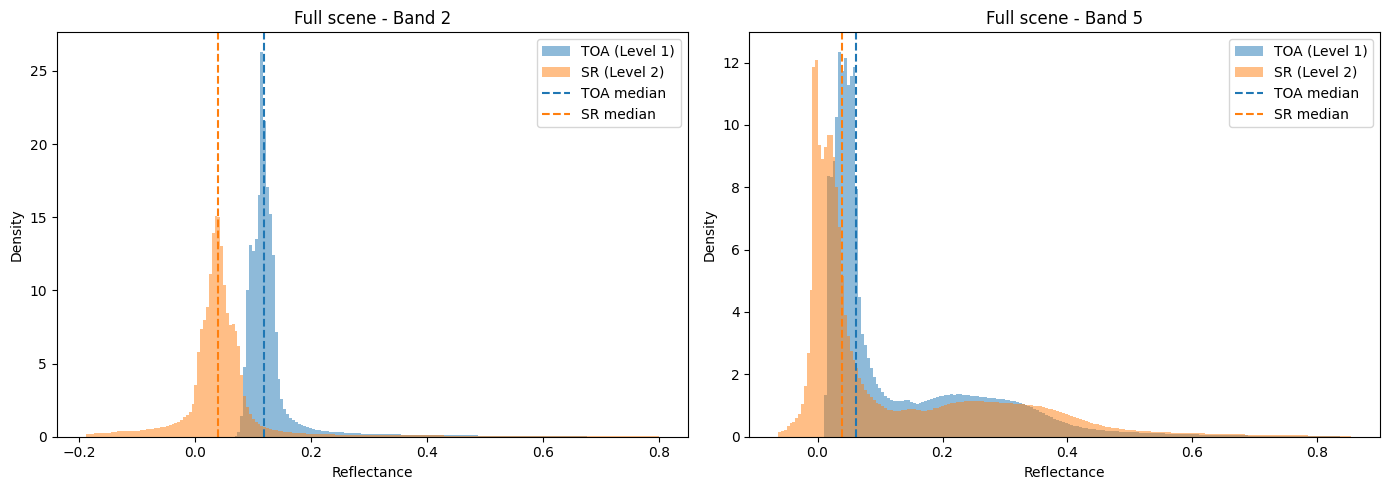

 Band      Pixels   TOA mean   TOA med   TOA std   SR mean    SR med    SR std   SR<0 %
    2    40319696     0.1331    0.1182    0.0664    0.0542    0.0402    0.1071   11.78%
    5    40561808     0.1301    0.0611    0.1319    0.1250    0.0387    0.1647   16.12%


In [14]:
BANDS = [2, 5]
N_BINS = 200
LOG_Y = False      # set True if the peaks hide the tails

fig, axes = plt.subplots(1, len(BANDS), figsize=(14, 5))
summary = []

for ax, band in zip(axes, BANDS):
    toa = loader.load_reflectance(LEVEL1_DIR, band)     # TOA, full scene
    sr = loader.load_reflectance(LEVEL2_DIR, band)      # SR, full scene
    if toa.shape != sr.shape:
        raise ValueError(f"Band {band}: TOA and SR shapes differ: {toa.shape} vs {sr.shape}")

    # Use only pixels that are valid in both products, so both histograms cover the same pixels
    valid = np.isfinite(toa) & np.isfinite(sr)
    toa_v = toa[valid]
    sr_v = sr[valid]
    del toa, sr, valid
    gc.collect()

    # Common bin range from a subsample, clipped to the 0.1-99.9 percentiles
    sample = np.concatenate([toa_v[::50], sr_v[::50]])
    lo, hi = np.percentile(sample, [0.1, 99.9])
    bins = np.linspace(lo, hi, N_BINS + 1)

    ax.hist(toa_v, bins=bins, density=True, alpha=0.5, label='TOA (Level 1)')
    ax.hist(sr_v, bins=bins, density=True, alpha=0.5, label='SR (Level 2)')
    ax.axvline(np.median(toa_v), color='C0', linestyle='--', label='TOA median')
    ax.axvline(np.median(sr_v), color='C1', linestyle='--', label='SR median')
    if LOG_Y:
        ax.set_yscale('log')
    ax.set_title(f"Full scene - Band {band}")
    ax.set_xlabel("Reflectance")
    ax.set_ylabel("Density")
    ax.legend()

    summary.append((band, toa_v.size,
                    toa_v.mean(), np.median(toa_v), toa_v.std(),
                    sr_v.mean(), np.median(sr_v), sr_v.std(),
                    np.mean(sr_v < 0)))
    del toa_v, sr_v, sample
    gc.collect()

plt.tight_layout()
plt.show()

print(f"{'Band':>5}{'Pixels':>12}{'TOA mean':>11}{'TOA med':>10}{'TOA std':>10}"
      f"{'SR mean':>10}{'SR med':>10}{'SR std':>10}{'SR<0 %':>9}")
for band, n, tm, tmed, tsd, sm, smed, ssd, neg in summary:
    print(f"{band:>5}{n:>12}{tm:>11.4f}{tmed:>10.4f}{tsd:>10.4f}"
          f"{sm:>10.4f}{smed:>10.4f}{ssd:>10.4f}{100 * neg:>8.2f}%")